In [72]:
import os

# Limit CPU thread pools before importing NumPy / PyTorch / SciPy / MONAI
os.environ["OMP_NUM_THREADS"] = "4"
os.environ["MKL_NUM_THREADS"] = "4"
os.environ["OPENBLAS_NUM_THREADS"] = "4"
os.environ["NUMEXPR_NUM_THREADS"] = "4"
os.environ["VECLIB_MAXIMUM_THREADS"] = "4"

import torch

torch.set_num_threads(4)
torch.set_num_interop_threads(2)

print("PyTorch intra-op threads:", torch.get_num_threads())
print("PyTorch inter-op threads:", torch.get_num_interop_threads())

RuntimeError: Error: cannot set number of interop threads after parallel work has started or set_num_interop_threads called

In [9]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from omegaconf import OmegaConf

from tqdm.auto import tqdm
from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    EnsureTyped,
)

from scripts.data_loader import ExtractSlabsAroundZ

cfg = OmegaConf.load(f"configs/default_config.yaml")
cfg = cfg["komondor"]
cfg["batch_size"] = 1

train_list = json.load(open(cfg["train_list"], "r"))


transform = Compose([
    LoadImaged(keys=["gt_dose"]),

    EnsureChannelFirstd(
        keys=["gt_dose"]
    ),

    ExtractSlabsAroundZ(
        keys=["gt_dose"],
        source_key="ray_source",
        slice_radius=15,
    ),

    EnsureTyped(
        keys=[
            "gt_dose",
            "condition",
            "ray_source",
            "ray_target",
        ],
        track_meta=True,
    ),
])

In [10]:
sample = transform(train_list[-10])

print(sample["gt_dose"].shape)
print(sample["condition"])

torch.Size([1, 446, 448, 31])
metatensor([1.7092e-01, 9.8529e-01, 1.9949e+02])


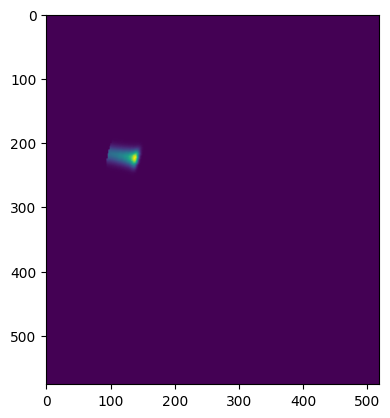

In [49]:
plt.imshow(sample["gt_dose"][0,:,:,16])

In [12]:
def get_beam_axis_2d(sample, flip_lps_to_ras=True):
    source = np.asarray(
        sample["ray_source"],
        dtype=np.float64,
    ).copy()

    target = np.asarray(
        sample["ray_target"],
        dtype=np.float64,
    ).copy()

    if flip_lps_to_ras:
        source[0] *= -1
        source[1] *= -1

        target[0] *= -1
        target[1] *= -1

    beam_dir_world = target - source
    beam_dir_world /= np.linalg.norm(beam_dir_world)

    affine = sample["gt_dose"].affine.detach().cpu().numpy()

    # world direction -> voxel direction
    voxel_dir = (
        np.linalg.inv(affine[:3, :3])
        @ beam_dir_world
    )

    # a [:,:,z] slice két tengelye
    axis_2d = voxel_dir[:2]

    norm = np.linalg.norm(axis_2d)

    if norm < 1e-8:
        return None

    axis_2d /= norm

    return axis_2d

In [13]:
def measure_beam_length_2d(
    sample,
    z_index=16,
    threshold=0.01,
):
    dose = (
        sample["gt_dose"][0, :, :, z_index]
        .detach()
        .cpu()
        .numpy()
    )

    if dose.max() <= 0:
        return None

    mask = (
        dose >= threshold * dose.max()
    )

    points = np.argwhere(mask).astype(np.float64)

    if len(points) < 2:
        return None

    axis = get_beam_axis_2d(sample)

    if axis is None:
        return None

    # minden pixel vetülete a beam tengelyére
    projection = points @ axis

    s_start = projection.min()
    s_end = projection.max()

    length_voxel_units = s_end - s_start

    # Egy egységnyi elmozdulás ezen a 2D voxelirányon
    # fizikailag hány mm?
    affine = sample["gt_dose"].affine.detach().cpu().numpy()

    delta_voxel = np.array([
        axis[0],
        axis[1],
        0.0,
    ])

    delta_world = (
        affine[:3, :3]
        @ delta_voxel
    )

    mm_per_unit = np.linalg.norm(
        delta_world
    )

    length_mm = (
        length_voxel_units
        * mm_per_unit
    )

    return float(length_mm)

In [14]:
length = measure_beam_length_2d(
    sample,
    z_index=16,
    threshold=0.01,
)

print(
    "Energy:",
    float(sample["condition"][2]),
    "MeV"
)

print(
    "True beam length:",
    length,
    "mm"
)

Energy: 199.49429321289062 MeV
True beam length: 251.2578447734642 mm


In [15]:
def plot_measured_beam(sample, z_index=16, threshold=0.01):
    dose = (
        sample["gt_dose"][0, :, :, z_index]
        .detach()
        .cpu()
        .numpy()
    )

    mask = (
        dose >= threshold * dose.max()
    )

    points = np.argwhere(mask).astype(np.float64)

    axis = get_beam_axis_2d(sample)

    projection = points @ axis

    s0 = projection.min()
    s1 = projection.max()

    # Dose-weighted centroid
    weights = dose[mask]

    center = np.sum(
        points * weights[:, None],
        axis=0,
    ) / weights.sum()

    center_projection = center @ axis

    p_start = (
        center
        + (s0 - center_projection) * axis
    )

    p_end = (
        center
        + (s1 - center_projection) * axis
    )

    length = measure_beam_length_2d(
        sample,
        z_index=z_index,
        threshold=threshold,
    )

    plt.figure(figsize=(8, 8))

    plt.imshow(dose)

    # matplotlib: x = második index, y = első index
    plt.plot(
        [p_start[1], p_end[1]],
        [p_start[0], p_end[0]],
        linewidth=2,
        label=f"Measured beam: {length:.1f} mm",
    )

    plt.scatter(
        p_start[1],
        p_start[0],
        s=60,
        label="Start",
    )

    plt.scatter(
        p_end[1],
        p_end[0],
        s=60,
        label="End",
    )

    plt.legend()
    plt.tight_layout()
    plt.show()

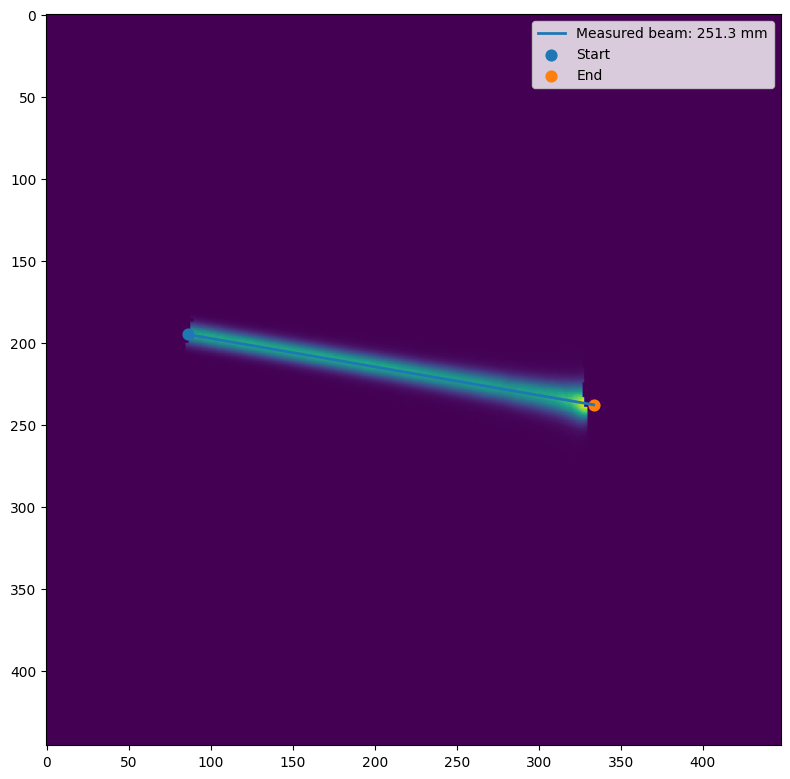

In [16]:
plot_measured_beam(
    sample,
    z_index=16,
    threshold=0.01,
)

In [29]:
n_samples = 2000
random_seed = 42

rng = np.random.default_rng(random_seed)

selected_indices = rng.choice(
    len(train_list),
    size=min(n_samples, len(train_list)),
    replace=False,
)

selected_data = [
    train_list[i]
    for i in selected_indices
]


results = []
errors = []

for item in tqdm(
    selected_data,
    desc=f"Measuring {len(selected_data)} beamlets",
):
    try:
        sample = transform(item)

        length = measure_beam_length_2d(
            sample,
            z_index=16,
            threshold=0.01,
        )

        if length is None:
            continue

        energy = float(
            sample["condition"][2]
        )

        path = item["gt_dose"]

        if "TH" in path:
            group = "TH"

        elif "AB" in path:
            group = "AB"

        else:
            group = "OTHER"

        results.append({
            "energy_mev": energy,
            "beam_length_mm": length,
            "group": group,
            "gt_dose": path,
        })

    except Exception as e:
        errors.append({
            "gt_dose": item["gt_dose"],
            "error": str(e),
        })


df = pd.DataFrame(results)
errors = pd.DataFrame(errors)

print("Selected:", len(selected_data))
print("Successfully analysed:", len(df))
print("Errors:", len(errors))

display(df.head())

Measuring 2000 beamlets:   0%|          | 0/2000 [00:00<?, ?it/s]

Selected: 2000
Successfully analysed: 2000
Errors: 0


,energy_mev,beam_length_mm,group,gt_dose
0,41.378799,41.402097,AB,//scratch/nr_dose/training/1ABB115/dose/Dose_B...
1,118.489700,115.087373,AB,//scratch/nr_dose/training/1ABB115/dose/Dose_B...
2,83.126602,93.537423,TH,//scratch/nr_dose/training/1THB021/dose/Dose_B...
3,187.464203,223.000000,AB,//scratch/nr_dose/training/1ABB036/dose/Dose_B...
4,118.489700,126.412084,TH,//scratch/nr_dose/training/1THB095/dose/Dose_B...


In [30]:
display(
    df.groupby("group")[
        ["energy_mev", "beam_length_mm"]
    ].describe()
)

energy_mev                                                           \
           count        mean        std        min        25%         50%   
group                                                                       
AB         993.0  134.092987  46.999281  31.729000  97.545898  140.354797   
TH        1007.0  106.798731  28.894898  41.378799  85.658699  104.168198   

                              beam_length_mm                                  \
              75%         max          count       mean        std       min   
group                                                                          
AB     174.807495  200.796600          993.0  165.92391  75.303738  20.51933   
TH     127.949699  184.709503         1007.0  172.83472  69.035520  38.77802   

                                                       
              25%         50%         75%         max  
group                                                  
AB     101.816182  167.787128  224.242926  358.242476  
TH     123.162698  173.689490  220.460718  369.703232

In [31]:
df["energy_bin"] = (
    np.round(
        df["energy_mev"] / 1.0
    )
    * 1.0
)


stats = (
    df
    .groupby(
        ["group", "energy_bin"]
    )["beam_length_mm"]
    .agg([
        "count",
        "mean",
        "std",
        "median",
        "min",
        "max",
    ])
    .reset_index()
)

display(stats)

,group,energy_bin,count,mean,std,median,min,max
0,AB,32.0,15,41.544846,20.519139,36.914770,20.519330,108.506298
1,AB,37.0,14,44.854735,23.489712,34.830043,22.862644,95.098047
2,AB,41.0,4,36.165186,7.223839,36.837611,27.973657,43.011865
3,AB,46.0,13,66.551795,37.245164,61.944783,28.945274,146.958796
4,AB,50.0,11,43.073203,12.310802,38.656862,32.673072,69.287721
...,...,...,...,...,...,...,...,...
148,TH,175.0,1,261.464607,NaN,261.464607,261.464607,261.464607
149,TH,176.0,4,283.596104,20.811509,283.096109,259.874065,308.318131
150,TH,179.0,2,246.483004,26.138915,246.483004,228.000000,264.966008
151,TH,182.0,1,294.884397,NaN,294.884397,294.884397,294.884397


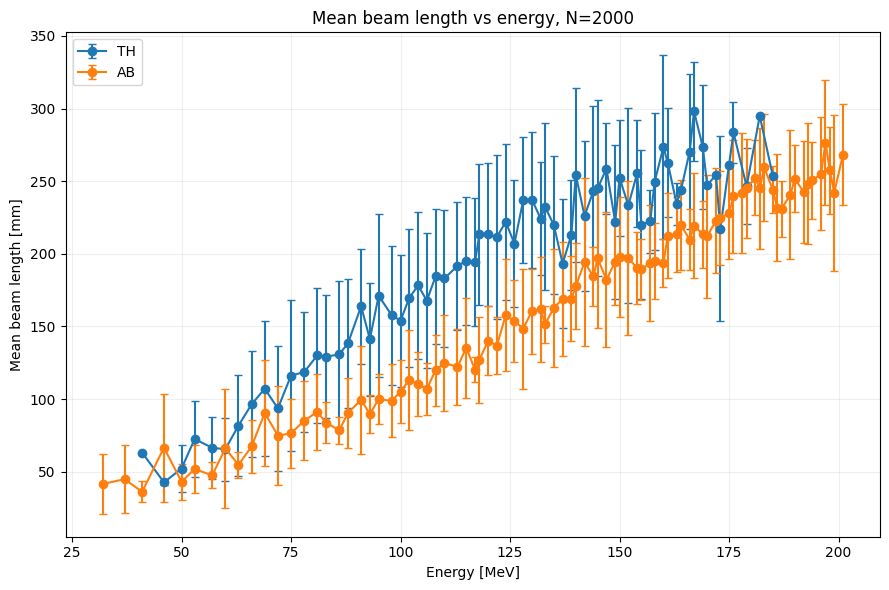

In [32]:
plt.figure(figsize=(9, 6))

for group in ["TH", "AB"]:
    sub = stats[
        stats["group"] == group
    ]

    plt.errorbar(
        sub["energy_bin"],
        sub["mean"],
        yerr=sub["std"],
        marker="o",
        capsize=3,
        label=group,
    )

plt.xlabel("Energy [MeV]")
plt.ylabel("Mean beam length [mm]")
plt.title(
    f"Mean beam length vs energy, N={len(df)}"
)

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

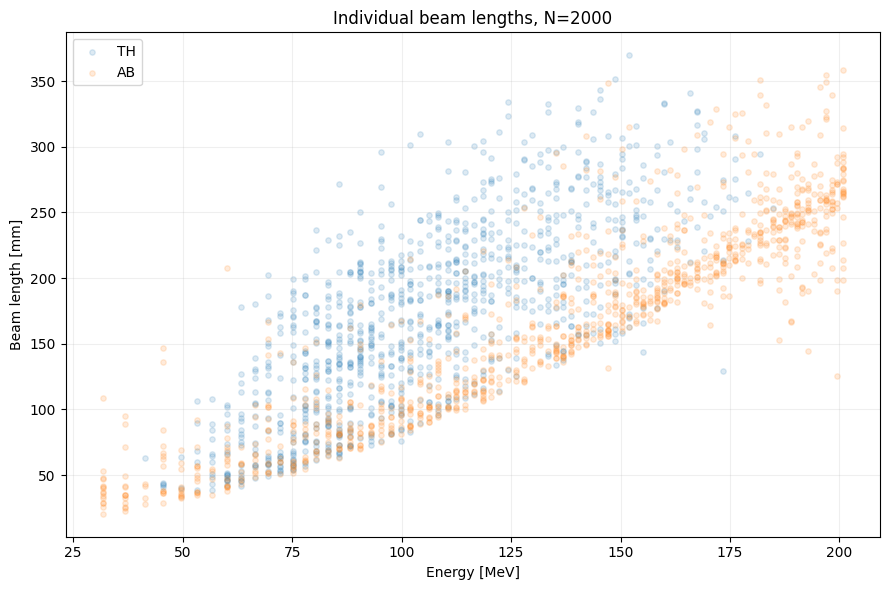

In [33]:
plt.figure(figsize=(9, 6))

for group in ["TH", "AB"]:
    sub = df[
        df["group"] == group
    ]

    plt.scatter(
        sub["energy_mev"],
        sub["beam_length_mm"],
        alpha=0.15,
        s=15,
        label=group,
    )

plt.xlabel("Energy [MeV]")
plt.ylabel("Beam length [mm]")
plt.title(
    f"Individual beam lengths, N={len(df)}"
)

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


TH
L(E) = 36.99015255 * E^0.500000 + -208.1400
a = 36.99015255 ± 17.52729191
b = 0.500000 ± 0.074035
c = -208.1400 ± 47.9871
RMSE = 16.07 mm
R² = 0.9329

AB
L(E) = 0.09815625 * E^1.485708 + 13.5085
a = 0.09815625 ± 0.02949000
b = 1.485708 ± 0.055065
c = 13.5085 ± 3.8743
RMSE = 10.34 mm
R² = 0.9771


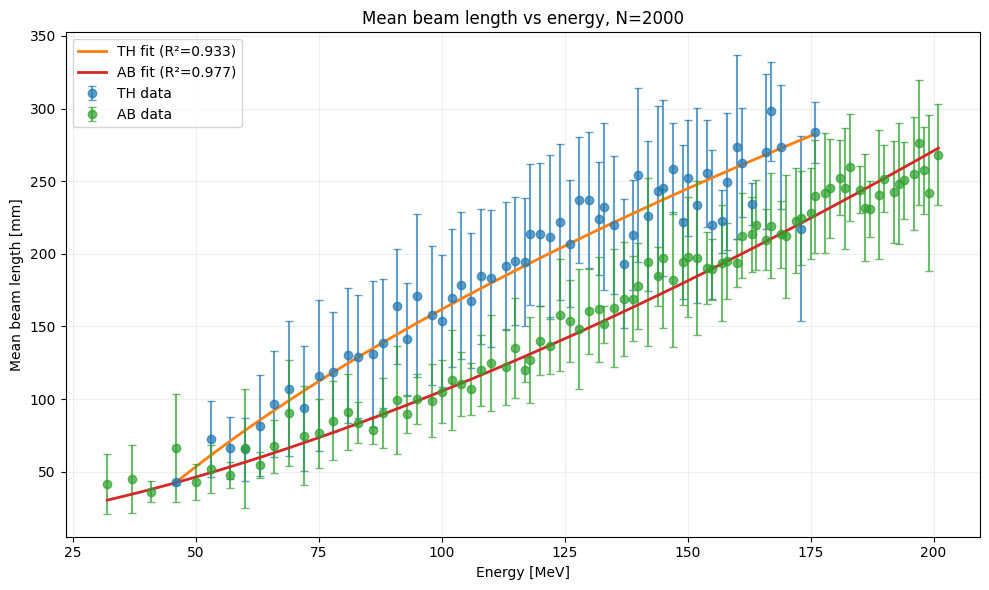

In [34]:
from scipy.optimize import curve_fit
import numpy as np
import matplotlib.pyplot as plt


def beam_length_model(E, a, b, c):
    return a * E**b + c


fit_results = {}


plt.figure(figsize=(10, 6))


for group in ["TH", "AB"]:

    sub = stats[
        stats["group"] == group
    ].copy()

    sub = sub.sort_values(
        "energy_bin"
    )

    # Olyan bineket használjunk,
    # amelyekben van elég sample
    sub = sub[
        sub["count"] >= 3
    ]

    x = sub[
        "energy_bin"
    ].to_numpy(
        dtype=np.float64
    )

    y = sub[
        "mean"
    ].to_numpy(
        dtype=np.float64
    )

    std = sub[
        "std"
    ].to_numpy(
        dtype=np.float64
    )

    count = sub[
        "count"
    ].to_numpy(
        dtype=np.float64
    )

    # Standard error of the mean
    sigma = std / np.sqrt(count)

    valid_sigma = (
        np.isfinite(sigma)
        & (sigma > 0)
    )

    fallback_sigma = np.nanmedian(
        sigma[valid_sigma]
    )

    if not np.isfinite(
        fallback_sigma
    ):
        fallback_sigma = 1.0

    sigma[
        ~valid_sigma
    ] = fallback_sigma


    # -------------------------------------
    # CURVE FIT
    # -------------------------------------

    popt, pcov = curve_fit(
        beam_length_model,
        x,
        y,
        sigma=sigma,
        absolute_sigma=True,
        p0=[
            0.01,
            1.7,
            0.0,
        ],
        bounds=(
            [
                0.0,
                0.5,
                -np.inf,
            ],
            [
                np.inf,
                3.0,
                np.inf,
            ],
        ),
        maxfev=20000,
    )


    fit_results[group] = {
        "params": popt,
        "cov": pcov,
    }


    a, b, c = popt

    parameter_errors = np.sqrt(
        np.diag(pcov)
    )

    da, db, dc = parameter_errors


    print()
    print(group)
    print(
        f"L(E) = "
        f"{a:.8f} * E^{b:.6f} "
        f"+ {c:.4f}"
    )

    print(
        f"a = {a:.8f} ± {da:.8f}"
    )

    print(
        f"b = {b:.6f} ± {db:.6f}"
    )

    print(
        f"c = {c:.4f} ± {dc:.4f}"
    )


    # -------------------------------------
    # FIT QUALITY
    # -------------------------------------

    y_pred = beam_length_model(
        x,
        *popt,
    )

    residuals = (
        y - y_pred
    )

    rmse = np.sqrt(
        np.mean(
            residuals**2
        )
    )

    ss_res = np.sum(
        residuals**2
    )

    ss_tot = np.sum(
        (
            y - y.mean()
        )**2
    )

    r2 = (
        1.0
        - ss_res / ss_tot
    )

    print(
        f"RMSE = {rmse:.2f} mm"
    )

    print(
        f"R² = {r2:.4f}"
    )


    fit_results[group][
        "rmse"
    ] = rmse

    fit_results[group][
        "r2"
    ] = r2


    # -------------------------------------
    # DATA
    # -------------------------------------

    plt.errorbar(
        x,
        y,
        yerr=std,
        fmt="o",
        capsize=3,
        alpha=0.7,
        label=f"{group} data",
    )


    # -------------------------------------
    # FITTED CURVE
    # -------------------------------------

    E_fit = np.linspace(
        x.min(),
        x.max(),
        500,
    )

    L_fit = beam_length_model(
        E_fit,
        *popt,
    )

    plt.plot(
        E_fit,
        L_fit,
        linewidth=2,
        label=(
            f"{group} fit "
            f"(R²={r2:.3f})"
        ),
    )


plt.xlabel(
    "Energy [MeV]"
)

plt.ylabel(
    "Mean beam length [mm]"
)

plt.title(
    f"Mean beam length vs energy, N={len(df)}"
)

plt.legend()

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.show()

In [35]:
for group in ["TH", "AB"]:

    a, b, c = fit_results[
        group
    ]["params"]

    print(
        f'{group}: '
        f'a={a:.10f}, '
        f'b={b:.10f}, '
        f'c={c:.10f}'
    )

TH: a=36.9901525502, b=0.5000000000, c=-208.1400268124
AB: a=0.0981562495, b=1.4857082045, c=13.5085456491


In [36]:
def predict_beam_length(
    energy,
    group,
):
    a, b, c = fit_results[
        group
    ]["params"]

    return beam_length_model(
        energy,
        a,
        b,
        c,
    )

In [37]:
energy = 140.4

print(
    "TH:",
    predict_beam_length(
        energy,
        "TH",
    ),
    "mm",
)

print(
    "AB:",
    predict_beam_length(
        energy,
        "AB",
    ),
    "mm",
)

TH: 230.1581622669683 mm
AB: 165.66097322854483 mm


In [38]:
import numpy as np
import torch
import matplotlib.pyplot as plt


def get_group(item):
    if "TH" in item["gt_dose"]:
        return "TH"

    if "AB" in item["gt_dose"]:
        return "AB"

    return None


def predict_beam_length(energy, group):
    a, b, c = fit_results[group]["params"]

    return float(
        beam_length_model(
            energy,
            a,
            b,
            c,
        )
    )


def make_fitted_energy_prior_2d(
    sample,
    item,
    z_index=16,
    sigma_mm=8.0,
    flip_lps_to_ras=True,
):
    dose = sample["gt_dose"]

    energy = float(
        sample["condition"][2]
    )

    group = get_group(item)

    if group is None:
        return None

    # ========================================================
    # Prediktált beam length az új fitből
    # ========================================================

    length_mm = predict_beam_length(
        energy,
        group,
    )

    # ========================================================
    # Ray geometria
    # ========================================================

    source = np.asarray(
        sample["ray_source"],
        dtype=np.float64,
    ).copy()

    target = np.asarray(
        sample["ray_target"],
        dtype=np.float64,
    ).copy()

    if flip_lps_to_ras:
        source[0] *= -1
        source[1] *= -1

        target[0] *= -1
        target[1] *= -1

    beam_dir_world = (
        target - source
    )

    beam_dir_world /= (
        np.linalg.norm(
            beam_dir_world
        ) + 1e-8
    )

    # ========================================================
    # Affine
    # ========================================================

    affine = dose.affine

    if torch.is_tensor(affine):
        affine = (
            affine
            .detach()
            .cpu()
            .numpy()
        )

    inv_affine = np.linalg.inv(
        affine
    )

    # ========================================================
    # Beam direction world -> voxel
    # ========================================================

    voxel_dir = (
        inv_affine[:3, :3]
        @ beam_dir_world
    )

    axis = voxel_dir[:2]

    axis_norm = np.linalg.norm(
        axis
    )

    if axis_norm < 1e-8:
        return None

    axis /= axis_norm

    # A beamre merőleges 2D irány
    perpendicular = np.array([
        -axis[1],
        axis[0],
    ])

    # ========================================================
    # mm / voxel-unit a beam irányában
    # ========================================================

    delta_voxel_long = np.array([
        axis[0],
        axis[1],
        0.0,
    ])

    delta_world_long = (
        affine[:3, :3]
        @ delta_voxel_long
    )

    mm_per_long = np.linalg.norm(
        delta_world_long
    )

    # ========================================================
    # mm / voxel-unit keresztirányban
    # ========================================================

    delta_voxel_trans = np.array([
        perpendicular[0],
        perpendicular[1],
        0.0,
    ])

    delta_world_trans = (
        affine[:3, :3]
        @ delta_voxel_trans
    )

    mm_per_trans = np.linalg.norm(
        delta_world_trans
    )

    # ========================================================
    # Fixed ray_target -> voxel koordináta
    # ========================================================

    target_h = np.array([
        target[0],
        target[1],
        target[2],
        1.0,
    ])

    target_voxel = (
        inv_affine @ target_h
    )[:3]

    target_2d = target_voxel[:2]

    # ========================================================
    # Fitted beam length voxel unitban
    # ========================================================

    length_voxel = (
        length_mm
        / mm_per_long
    )

    # fitted source:
    # target FIX, innen visszafelé L(E)
    pred_source_2d = (
        target_2d
        - length_voxel * axis
    )

    # ========================================================
    # 2D grid
    # ========================================================

    X = dose.shape[1]
    Y = dose.shape[2]

    xx, yy = np.meshgrid(
        np.arange(X),
        np.arange(Y),
        indexing="ij",
    )

    points = np.stack(
        [xx, yy],
        axis=-1,
    ).astype(np.float64)

    relative = (
        points
        - pred_source_2d
    )

    # ========================================================
    # Longitudinal coordinate
    # ========================================================

    longitudinal_voxel = (
        relative @ axis
    )

    longitudinal_mm = (
        longitudinal_voxel
        * mm_per_long
    )

    # ========================================================
    # Transverse coordinate
    # ========================================================

    transverse_voxel = (
        relative @ perpendicular
    )

    transverse_mm = (
        transverse_voxel
        * mm_per_trans
    )

    # ========================================================
    # Gaussian tube
    # ========================================================

    transverse_gaussian = np.exp(
        -0.5
        * (
            transverse_mm
            / sigma_mm
        )**2
    )

    # Csak fitted source -> fixed target között
    longitudinal_mask = (
        (longitudinal_mm >= 0.0)
        & (longitudinal_mm <= length_mm)
    )

    prior = (
        transverse_gaussian
        * longitudinal_mask
    )

    if prior.max() > 0:
        prior /= prior.max()

    return prior, {
        "group": group,
        "energy": energy,
        "length_mm": length_mm,
        "axis": axis,
        "target_2d": target_2d,
        "pred_source_2d": pred_source_2d,
        "mm_per_long": mm_per_long,
        "mm_per_trans": mm_per_trans,
    }

In [39]:
def measure_gt_length_for_plot(
    sample,
    z_index=16,
    threshold=0.01,
):
    dose = (
        sample["gt_dose"][
            0, :, :, z_index
        ]
        .detach()
        .cpu()
        .numpy()
    )

    if dose.max() <= 0:
        return None

    mask = (
        dose
        >= threshold * dose.max()
    )

    points = np.argwhere(
        mask
    ).astype(np.float64)

    if len(points) < 2:
        return None

    source = np.asarray(
        sample["ray_source"],
        dtype=np.float64,
    ).copy()

    target = np.asarray(
        sample["ray_target"],
        dtype=np.float64,
    ).copy()

    source[0] *= -1
    source[1] *= -1

    target[0] *= -1
    target[1] *= -1

    beam_dir_world = (
        target - source
    )

    beam_dir_world /= (
        np.linalg.norm(
            beam_dir_world
        ) + 1e-8
    )

    affine = (
        sample["gt_dose"]
        .affine
        .detach()
        .cpu()
        .numpy()
    )

    voxel_dir = (
        np.linalg.inv(
            affine[:3, :3]
        )
        @ beam_dir_world
    )

    axis = voxel_dir[:2]
    axis /= np.linalg.norm(axis)

    projection = (
        points @ axis
    )

    delta_voxel = np.array([
        axis[0],
        axis[1],
        0.0,
    ])

    delta_world = (
        affine[:3, :3]
        @ delta_voxel
    )

    mm_per_unit = np.linalg.norm(
        delta_world
    )

    length_mm = (
        projection.max()
        - projection.min()
    ) * mm_per_unit

    return float(length_mm)

In [40]:
def plot_fitted_prior_examples(
    train_list,
    n_per_group=4,
    seed=42,
    z_index=16,
    sigma_mm=8.0,
    threshold=0.01,
):
    rng = np.random.default_rng(
        seed
    )

    th_indices = [
        i
        for i, item in enumerate(train_list)
        if "TH" in item["gt_dose"]
    ]

    ab_indices = [
        i
        for i, item in enumerate(train_list)
        if "AB" in item["gt_dose"]
    ]

    selected = []

    selected.extend(
        rng.choice(
            th_indices,
            size=min(
                n_per_group,
                len(th_indices),
            ),
            replace=False,
        )
    )

    selected.extend(
        rng.choice(
            ab_indices,
            size=min(
                n_per_group,
                len(ab_indices),
            ),
            replace=False,
        )
    )

    n_rows = len(selected)

    fig, axes = plt.subplots(
        n_rows,
        3,
        figsize=(
            15,
            4 * n_rows,
        ),
    )

    if n_rows == 1:
        axes = axes[None, :]

    for row, idx in enumerate(
        selected
    ):
        item = train_list[idx]

        sample = transform(item)

        result = (
            make_fitted_energy_prior_2d(
                sample,
                item,
                z_index=z_index,
                sigma_mm=sigma_mm,
            )
        )

        if result is None:
            continue

        prior, info = result

        gt = (
            sample["gt_dose"][
                0, :, :, z_index
            ]
            .detach()
            .cpu()
            .numpy()
        )

        gt_norm = (
            gt
            / (gt.max() + 1e-8)
        )

        gt_length = (
            measure_gt_length_for_plot(
                sample,
                z_index=z_index,
                threshold=threshold,
            )
        )

        fitted_length = info[
            "length_mm"
        ]

        difference = (
            fitted_length
            - gt_length
        )

        # ========================================
        # GT
        # ========================================

        axes[row, 0].imshow(
            gt_norm,
            cmap="viridis",
        )

        axes[row, 0].set_title(
            f"Ground truth\n"
            f"{info['group']} | "
            f"E={info['energy']:.1f} MeV\n"
            f"L_GT={gt_length:.1f} mm"
        )

        # ========================================
        # PRIOR
        # ========================================

        axes[row, 1].imshow(
            prior,
            cmap="viridis",
            vmin=0,
            vmax=1,
        )

        axes[row, 1].set_title(
            f"Fitted energy prior\n"
            f"L_fit={fitted_length:.1f} mm\n"
            f"ΔL={difference:+.1f} mm"
        )

        # ========================================
        # OVERLAY
        # ========================================

        axes[row, 2].imshow(
            gt_norm,
            cmap="gray",
            vmin=0,
            vmax=1,
        )

        axes[row, 2].imshow(
            prior,
            cmap="magma",
            alpha=0.45,
            vmin=0,
            vmax=1,
        )

        axes[row, 2].set_title(
            "GT + fitted prior"
        )

        # fitted start + target
        source_2d = info[
            "pred_source_2d"
        ]

        target_2d = info[
            "target_2d"
        ]

        axes[row, 2].scatter(
            source_2d[1],
            source_2d[0],
            s=30,
            marker="o",
            label="Fitted start",
        )

        axes[row, 2].scatter(
            target_2d[1],
            target_2d[0],
            s=30,
            marker="x",
            label="Fixed ray target",
        )

        for col in range(3):
            axes[row, col].axis(
                "off"
            )

        axes[row, 2].legend(
            loc="upper right",
            fontsize=7,
        )

    plt.tight_layout()
    plt.show()

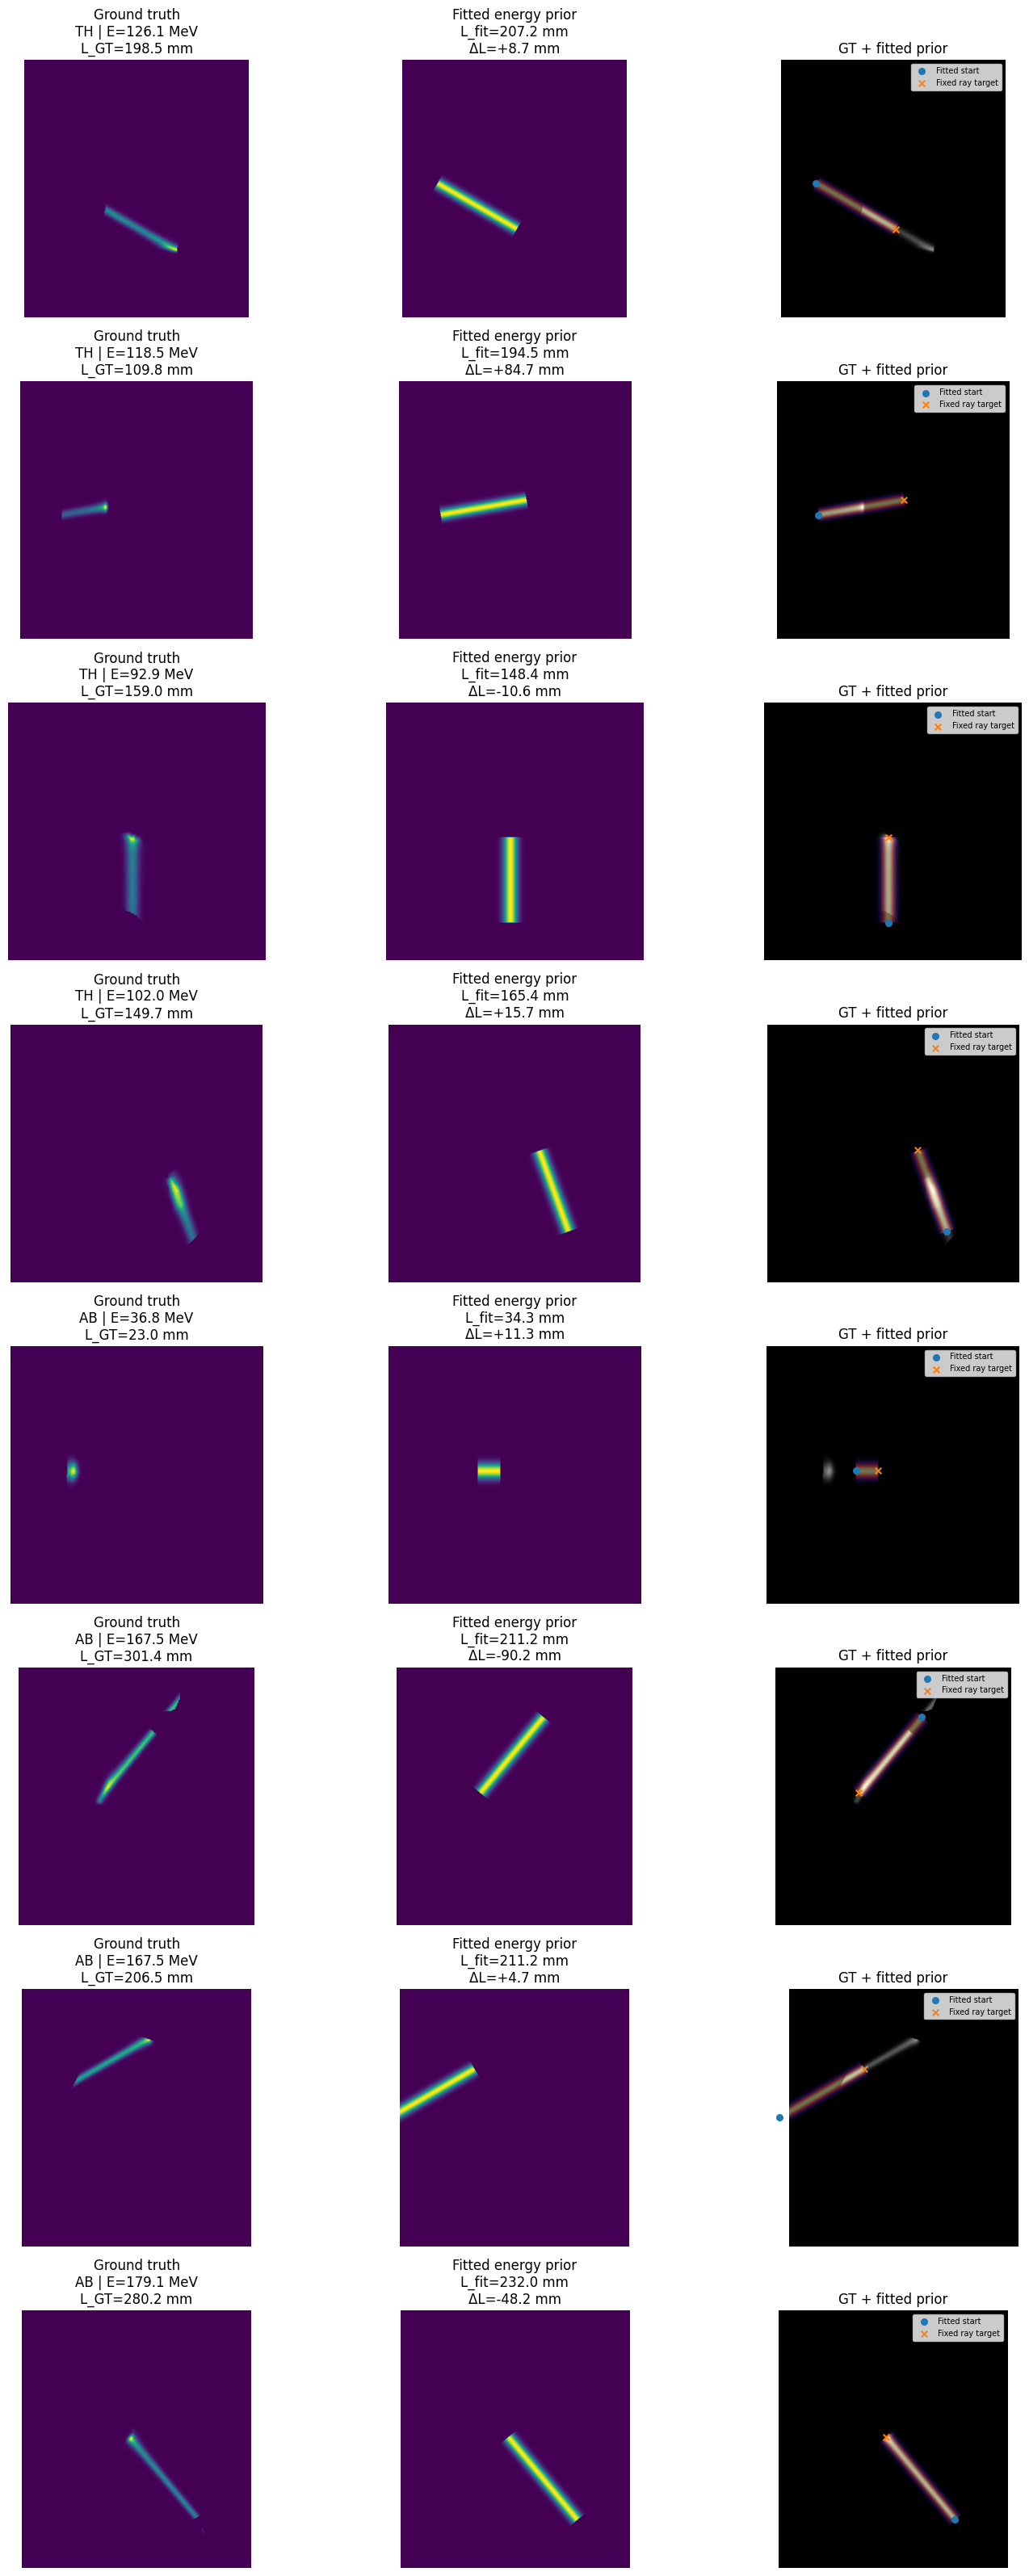

In [41]:
plot_fitted_prior_examples(
    train_list,
    n_per_group=4,
    seed=42,
    z_index=16,
    sigma_mm=8.0,
    threshold=0.01,
)